# CellSegNet — nnUNet-style 3D Cell Segmentation

In [123]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
import sys
sys.path.insert(0, "../src")

import glob
import json
import torch
import argparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from pathlib import Path

In [11]:
from segmentation.train import train
from segmentation.targets import compute_all_targets

from segmentation.dataset import CellSegDataset
from segmentation.losses import CellSegLoss

from segmentation.plot import plot_sample, plot_offsets, plot_preds
from segmentation.predict import load_model, predict_volume, postprocess, sigmoid
from segmentation.post_process import postprocess

In [55]:
from params import *
from utils.metrics import *
from utils.plot import *
from utils.logger import Config

### Data

In [23]:
DATA_DIR = Path("../output/segs_3/")

npz_files = sorted(DATA_DIR.glob("*.npz"))
npz_files = [str(f) for f in npz_files if "targets" not in str(f)]
print(f"Found {len(npz_files)} training file(s)")

Found 10000 training file(s)


In [24]:
data = np.load(npz_files[0], allow_pickle=False)

print("Keys and shapes:")
for k in data.files:
    try:
        v = data[k]
        print(f"  {k:12s}  shape={v.shape}  dtype={v.dtype}  range={v.min()}-{v.max()}")
    except Exception as e:
        print(f"  {k:12s}  *** corrupt: {e} ***")

img = data['img'] # (D, H, W) uint16
masks = data['masks']  # (D, H, W) uint16 instance labels
centroids = data['centroids']  # (N, 3) int32

fg_soft = (masks > 0).astype(np.float32)

D, H, W = img.shape
print(f"\nVolume    : {D} × {H} × {W}")
print(
    f"Cells     : {len(np.unique(masks)) - 1} in masks | {len(centroids)} centroids (may span multiple frames)"
)

Keys and shapes:
  img           shape=(64, 256, 256)  dtype=uint16  range=0-65535
  masks         shape=(64, 256, 256)  dtype=uint16  range=0-201
  cellpose_masks  shape=(64, 256, 256)  dtype=uint16  range=0-36
  flows         shape=(64, 256, 256, 3)  dtype=uint8  range=0-255
  probas        shape=(64, 256, 256)  dtype=float32  range=-9.908781051635742-8.926309585571289
  centroids     shape=(201, 3)  dtype=int32  range=4-242

Volume    : 64 × 256 × 256
Cells     : 201 in masks | 201 centroids (may span multiple frames)


In [25]:
%%time
heatmap, offsets, centroid_map = compute_all_targets(masks, sigma=3.0)

print(f"heatmap : {heatmap.shape}  range [{heatmap.min():.3f}, {heatmap.max():.3f}]")
print(
    f"offsets : {offsets.shape}  range [{offsets.min():.3f}, {offsets.max():.3f}]  (normalised to ~[-1,1])"
)
print(f"Cells derived from masks: {len(centroid_map)}")

heatmap : (64, 256, 256)  range [0.000, 1.000]
offsets : (3, 64, 256, 256)  range [-25.556, 25.444]  (normalised to ~[-1,1])
Cells derived from masks: 201
CPU times: user 774 ms, sys: 67.7 ms, total: 842 ms
Wall time: 841 ms


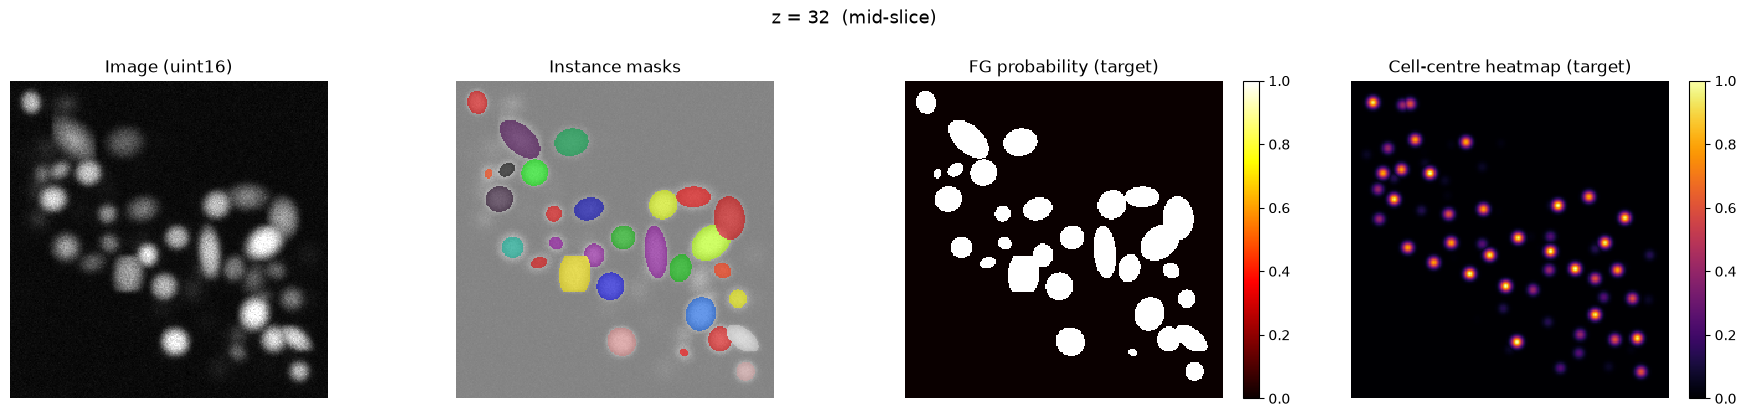

In [26]:
plot_sample(img, masks, fg_soft, heatmap, z=32)

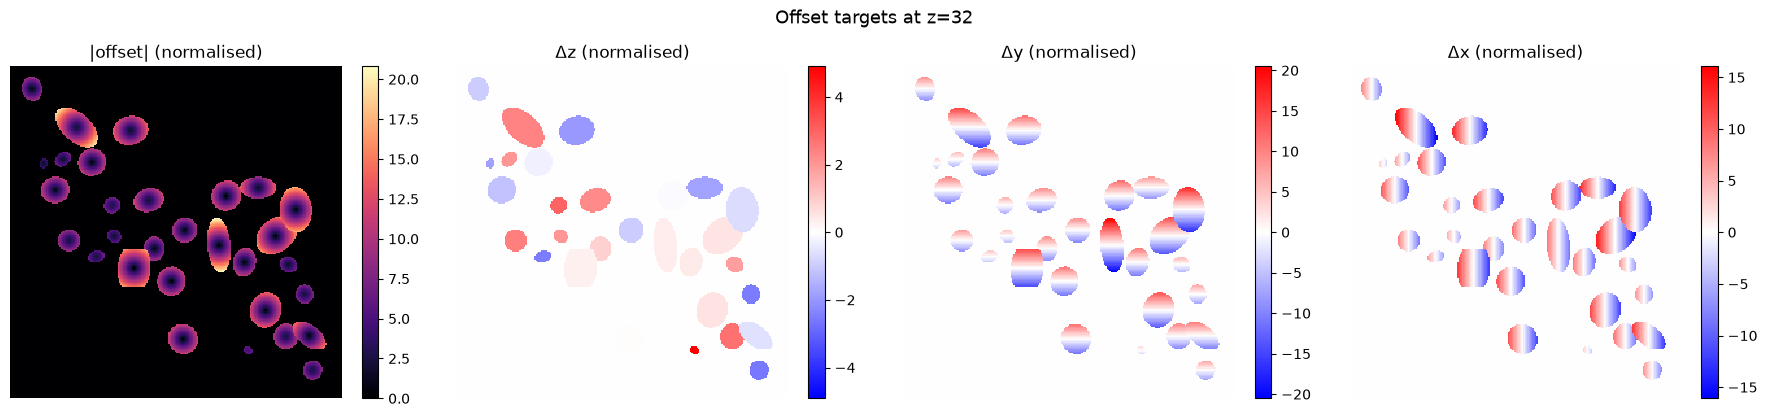

In [27]:
plot_offsets(offsets)

### Dataset

In [28]:
ds = CellSegDataset(
    str(DATA_DIR), sigma=3.0, augment=False, use_cellpose=True
)

print(f"Dataset: {len(ds)} sample(s)")

Dataset: 10000 sample(s)


In [29]:
# ds.precompute_targets()

In [30]:
sample = ds[0]
print("Sample keys/shapes:")
for k, v in sample.items():
    print(f"  {k:10s}  {tuple(v.shape)}  {v.dtype}\t range={v.min():.3f}-{v.max():.3f}")

Sample keys/shapes:
  image       (1, 64, 256, 256)  torch.float32	 range=0.000-1.000
  fg          (64, 256, 256)  torch.float32	 range=0.000-1.000
  heatmap     (64, 256, 256)  torch.float32	 range=0.000-1.000
  offsets     (3, 64, 256, 256)  torch.float32	 range=-25.556-25.444
  fg_mask     (64, 256, 256)  torch.bool	 range=0.000-1.000


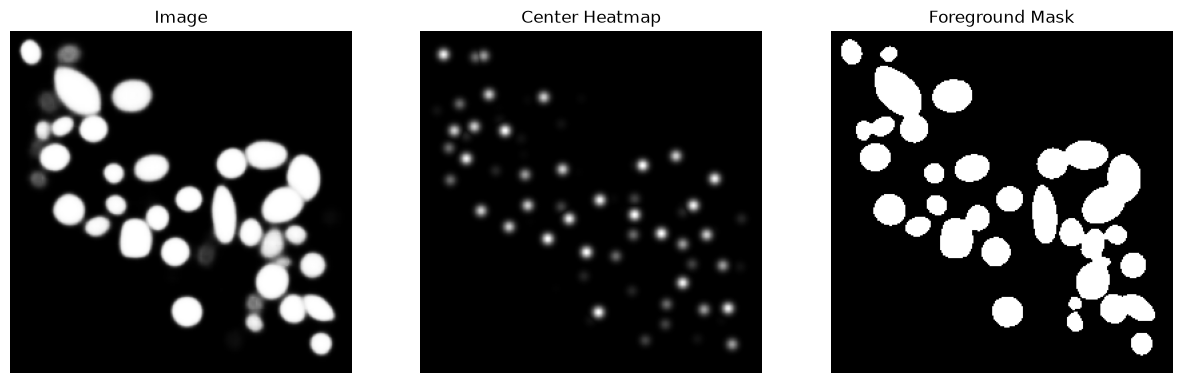

In [85]:
z = 32
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(sample["image"][0][z], cmap="gray")
plt.axis(False)
plt.title("Image")
plt.subplot(1, 3, 2)
plt.imshow(sample["heatmap"][z], cmap="gray")
plt.axis(False)
plt.title("Center Heatmap")
plt.subplot(1, 3, 3)
plt.imshow(sample["fg_mask"][z], cmap="gray")
plt.axis(False)
plt.title("Foreground Mask")
plt.show()

In [32]:
%%time
data = np.load(ds.files[0])
# sample = ds[0]

CPU times: user 483 μs, sys: 156 μs, total: 639 μs
Wall time: 620 μs


### Model

In [130]:
from model_zoo.models_seg import define_model as define_model_seg

In [131]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [132]:
model = define_model_seg(
    "Unet",
    "resnet18",
    num_classes=1,
    num_classes_aux=0,
    increase_stride=False,
    use_cls=False,
    n_channels=1,
    use_3d=True,
    verbose=0,
    heads={"fg_logits": 1, "heatmap_logits": 1, "offsets": 3}
)
model.to(device)
print(f"Parameters: {model.count_parameters() / 1e6:.1f}M")

Parameters: 42.6M


In [133]:
y = model(sample["image"].unsqueeze(0).to(device))

for k in y:
    print(k, y[k].shape)

torch.Size([1, 256, 4, 16, 16])
torch.Size([1, 128, 8, 32, 32])
torch.Size([1, 64, 16, 64, 64])
torch.Size([1, 32, 32, 128, 128])
torch.Size([1, 16, 64, 256, 256])
fg_logits torch.Size([1, 1, 64, 256, 256])
heatmap_logits torch.Size([1, 1, 64, 256, 256])
offsets torch.Size([1, 3, 64, 256, 256])


In [135]:
model.model.segmentation_head

SegmentationHead(
  (0): Conv3d(16, 5, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
  (1): Identity()
  (2): Activation(
    (activation): Identity()
  )
)

### Inference

In [103]:
log_folder = "../logs/2026-08-11/8/"

args = Config(json.load(open(log_folder + "args.json", "r")))

In [104]:
checkpoints = sorted(glob.glob(log_folder + "*.pt"))
if not checkpoints:
    print("No checkpoint found — run training first.")
else:
    ckpt_path = checkpoints[-1]  # latest checkpoint
    print(f"Loading: {ckpt_path}")

Loading: ../logs/2026-08-11/8/ckpt_01000.pt


In [105]:
infer_model = load_model(str(ckpt_path), in_channels=1, device=device)

In [106]:
sample_name = "6bba_09961292"
frame = 1
    
nodes = pd.read_csv(NODES_FOLDER + f"{sample_name}.csv")

data = np.load("../output/cellpose/" + f"{sample_name}_{frame}.npz")

gt = nodes[nodes["t"] == frame][["z", "y", "x"]].values

In [108]:
from segmentation.predict import predict_volume

In [109]:
preds = predict_volume(infer_model, data, use_cellpose=True, device=device)
print("Raw predictions:")
for k, v in preds.items():
    print(f"  {k:20s}  {v.shape}  [{v.min():.3f}, {v.max():.3f}]")

5.240811e-05 0.99953735
Raw predictions:
  fg_logits             (64, 256, 256)  [-21.328, 27.922]
  heatmap_logits        (64, 256, 256)  [-13.875, 1.641]
  offsets               (3, 64, 256, 256)  [-14.250, 16.094]


In [136]:
pred_masks, pred_centroids = postprocess(
    preds,
    # fg_thresh=0.5,
    # vote_sigma=2.0,
    # nms_size=7,
    # vote_thresh_rel=0.1,
    # min_vote_voxels=10,
    fg_prob=sigmoid(data['probas'])
)

n_pred = len(pred_centroids)
print(f"Predicted cells : {n_pred}")

Predicted cells : 301


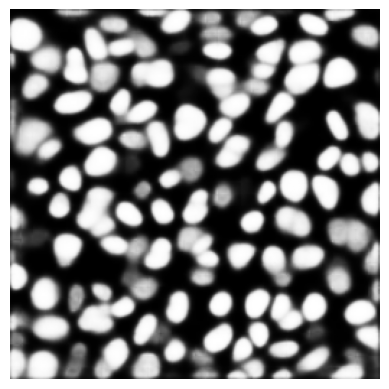

In [112]:
plt.imshow(sigmoid(data['probas'][z]), cmap="gray")
plt.axis(False)
plt.show()

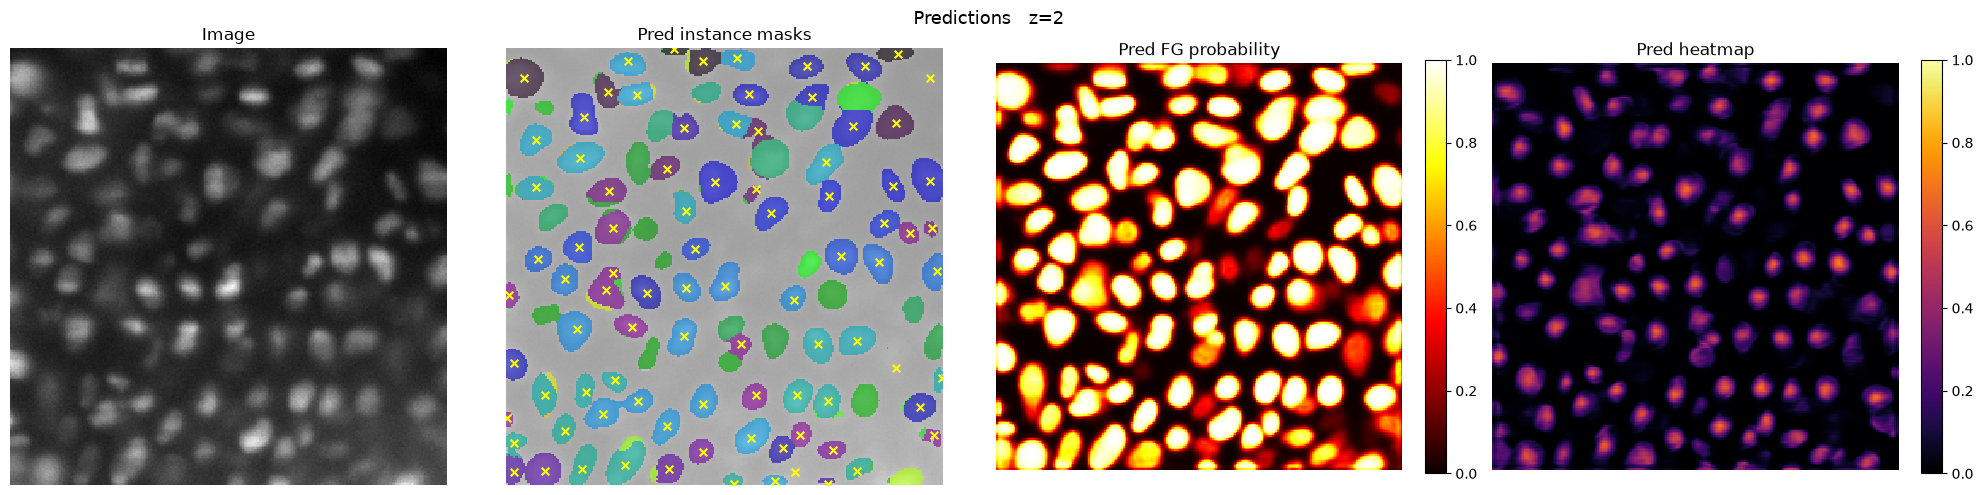

In [140]:
z = 2

pred_fg = sigmoid(preds["fg_logits"])  # (D, H, W)  in [0,1]
pred_fg = sigmoid(data["probas"])  # (D, H, W)  in [0,1]
pred_heatmap = sigmoid(preds["heatmap_logits"])  # (D, H, W)  in [0,1]
pred_offsets = preds["offsets"]  # (3, D, H, W) normalised

plot_preds(
    data['img'],
    pred_masks=pred_masks,
    pred_centroids=pred_centroids,
    pred_fg=pred_fg,
    pred_heatmap=pred_heatmap,
    z=z
)

In [138]:
pairs, matched_gt, unmatched_gt = match_frame_nodes(
    pred_centroids,
    gt,
    t=frame,
    scale=SCALE,
    max_distance=7,
)

print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes')

-> Matched 21 out of 21 GT nodes


/data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/cellpose/utils.py:203: RuntimeWarning: invalid value encountered in cast
  slices = find_objects(masks.astype(int))


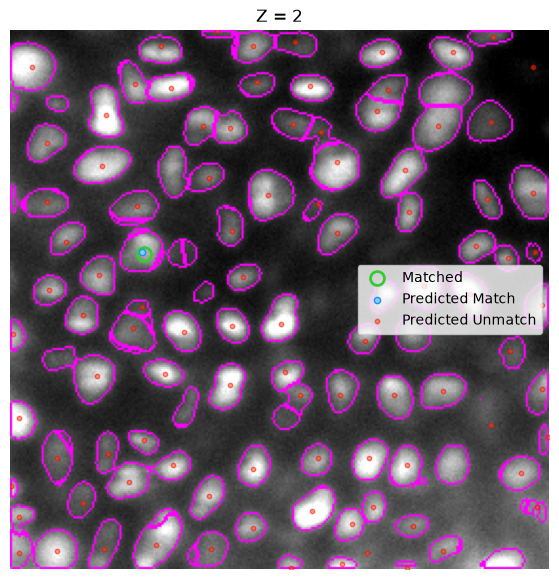

In [139]:
mask = np.where(pred_masks > 0, pred_masks, np.nan)
tol = 3

# ids = np.unique(unmatched_gt[:, 0]) if len(unmatched_gt) > 0 else [7]
ids = np.unique(gt[:, 0])

for i in ids:    
    plt.figure(figsize=(7, 7))
    plt.title(f"Z = {i}")
    plot_contours(data['img'][i], mask[i])
    # break
    scatter_plot_center_preds(
        pred_centroids, matched_gt, unmatched_gt, frame=i, tol=tol
    )
    plt.show()

    break

#### Save predictions

In [ ]:
SAVE_DIR = MODEL_DIR / "preds"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
out_path = SAVE_DIR / "pred_vol_00000.npz"

np.savez_compressed(
    out_path,
    masks=pred_masks,
    centroids=pred_centroids,
    fg_prob=pred_fg,
    heatmap=pred_heatmap,
)
print(f"Saved to {out_path}")

Done 